<a href="https://colab.research.google.com/github/mrayhanz/PCVK-Ganjil-2026/blob/main/week6_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhamad Rayhan Zamzami

Nim : 244107020027

Kelas : TI-3G

Absen : 19

In [ ]:
NAMA = 'Muhammad Rayhan Zamzami'
NIM = '244107020027' # ganti dengan NIM sendiri
print(NAMA, NIM)

Muhammad Rayhan Zamzami 244107020027


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

In [ ]:
# Fungsi convolution 2D
def convolution2d(image, kernel, stride=1, padding=0):
    height, width = image.shape[0], image.shape[1]
    kH, kW = kernel.shape

    # 1. ukuran output (untuk loop)
    out_h = (height + 2*padding - kH) // stride + 1
    out_w = (width  + 2*padding - kW) // stride + 1
    output = np.zeros((out_h, out_w), dtype=np.float32)

    # 2. mulai loop dari (0,0)
    for i in range(out_h):
        for j in range(out_w):
            total = 0
            for m in range(kH):
                for n in range(kW):
                    # koordinat di gambar ASLI
                    y = i*stride + m - padding
                    x = j*stride + n - padding

                    y = min(max(y, 0), height - 1)
                    x = min(max(x, 0), width - 1)
                    pixel = image[y, x]

                    total += pixel * kernel[m, n]

            # 4. simpan ke koordinat sekarang
            output[i, j] = total

    return output

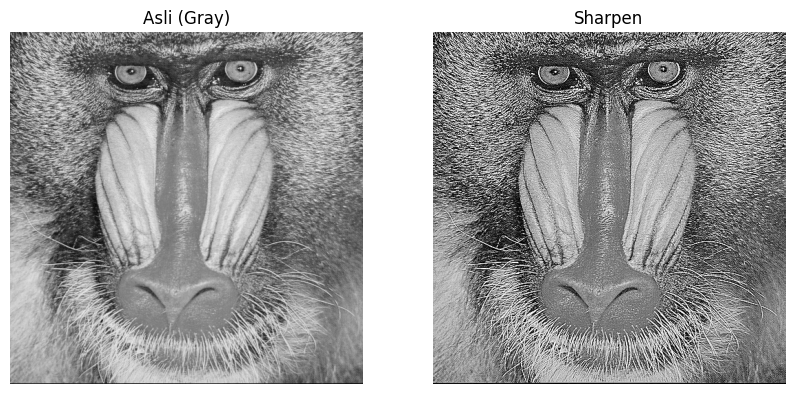

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK-2025/image/mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

kernel_sharpen = np.array([[0, -1, 0], [-1,5,-1], [0,-1,0]])

# simpan hasilnya ke variabel
hasil = convolution2d(img_gray, kernel_sharpen, 1, 2)
hasil = np.clip(hasil, 0, 255).astype(np.uint8)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_gray, cmap='gray')
plt.title('Asli (Gray)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(hasil, cmap='gray')
plt.title('Sharpen')
plt.axis('off')

plt.show()

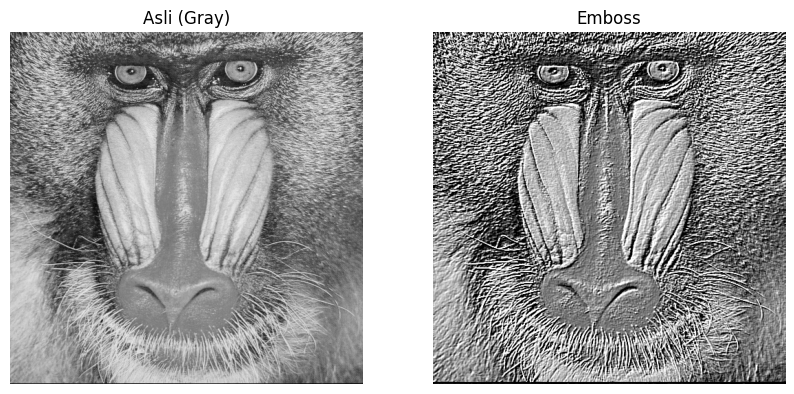

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK-2025/image/mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

kernel_emboss = np.array([[-2, -1, 0], [-1,1,1], [0,1,2]])

# simpan hasilnya ke variabel
hasil = convolution2d(img_gray, kernel_emboss, 1, 2)
hasil = np.clip(hasil, 0, 255).astype(np.uint8)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_gray, cmap='gray')
plt.title('Asli (Gray)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(hasil, cmap='gray')
plt.title('Emboss')
plt.axis('off')

plt.show()


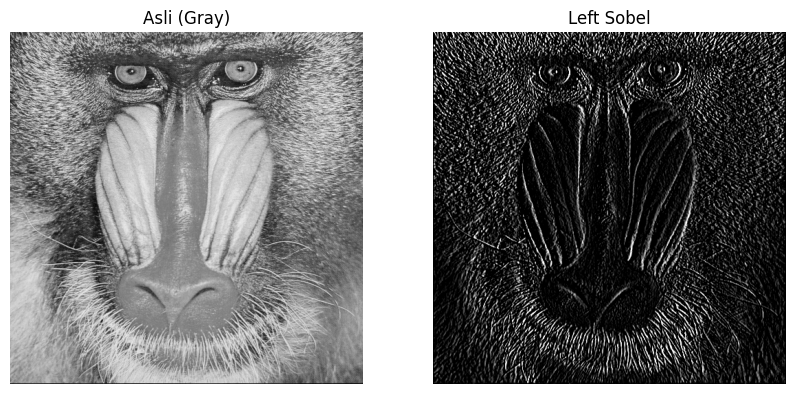

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK-2025/image/mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

kernel_left_sobel = np.array([[1, 0, -1], [2,0,-2], [1,0,-1]])

# simpan hasilnya ke variabel
hasil = convolution2d(img_gray, kernel_left_sobel, 1, 2)
hasil = np.clip(hasil, 0, 255).astype(np.uint8)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_gray, cmap='gray')
plt.title('Asli (Gray)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(hasil, cmap='gray')
plt.title('Left Sobel')
plt.axis('off')

plt.show()

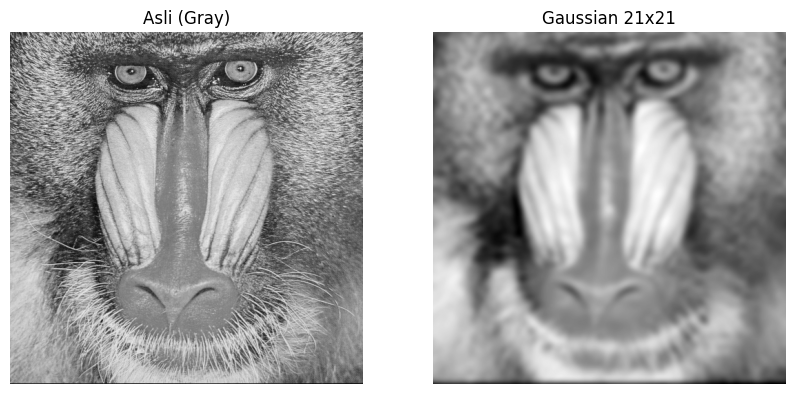

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK-2025/image/mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

kernel_size = 21
sigma = math.sqrt(kernel_size)

gaussian_kernel = cv.getGaussianKernel(kernel_size, sigma)   # bentuk (21, 1)
gauss_kernel = gaussian_kernel @ gaussian_kernel.transpose() # jadi (21, 21)

hasil = convolution2d(img_gray, gauss_kernel, 1, kernel_size // 2)
hasil = np.clip(hasil, 0, 255).astype(np.uint8)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_gray, cmap='gray')
plt.title('Asli (Gray)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(hasil, cmap='gray')
plt.title('Gaussian 21x21')
plt.axis('off')

plt.show()

# Filter Library

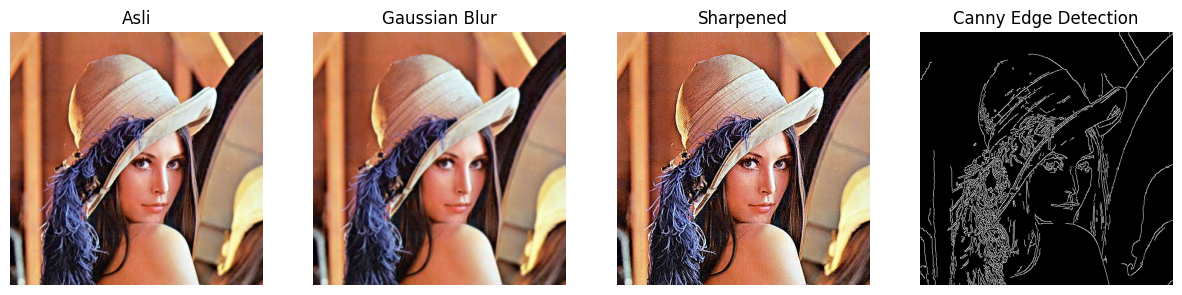

In [ ]:
def show_side_by_side(images, titles, figsize=(15,5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        if len(img.shape) == 2:  # grayscale
            plt.subplot(1, len(images), i+1)
            plt.imshow(img, cmap="gray")
        else:  # color
            plt.subplot(1, len(images), i+1)
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

img = cv.imread('/content/drive/MyDrive/PCVK-2025/image/lena.jpg')
img_gray = cv.cvtColor(img,cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(img, (7,7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)
show_side_by_side([img, blur, sharpened, edges],
                  ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"])

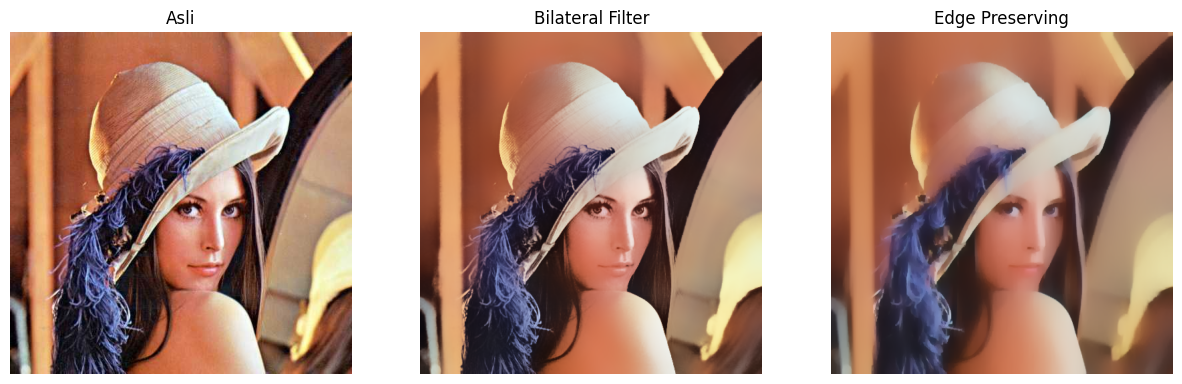

In [ ]:
# Bilateral Filter
bilateral = cv.bilateralFilter(img, 50, 100, 100)

# Edge Preserving
edge_preserved = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

show_side_by_side([img, bilateral, edge_preserved],
                  ["Asli", "Bilateral Filter", "Edge Preserving"])

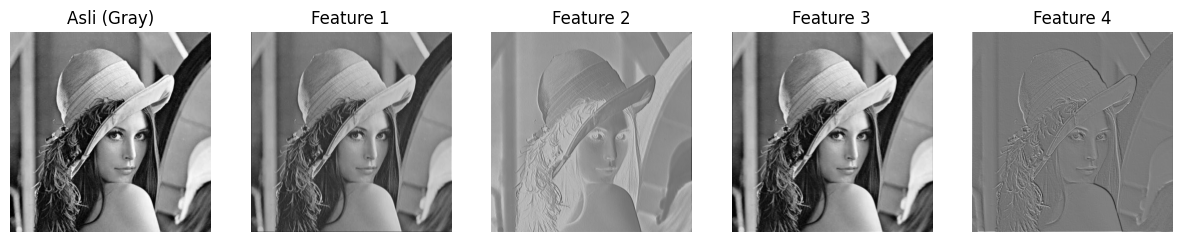

In [ ]:
#Filter Feature Map yang digunakan pada CNN, Lakukan running code bagian ini beberapa kali dan perhatikan hasilnya
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

    def forward(self, x):
        return self.conv1(x)

model = SimpleCNN()

# Ubah gambar ke tensor
img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

# Hasil CNN
with torch.no_grad():
    features = model(img_tensor)

# Visualisasi feature maps
feature_maps = [features[0,i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_gray] + feature_maps, ["Asli (Gray)"] + [f"Feature {i+1}" for i in range(len(feature_maps))])

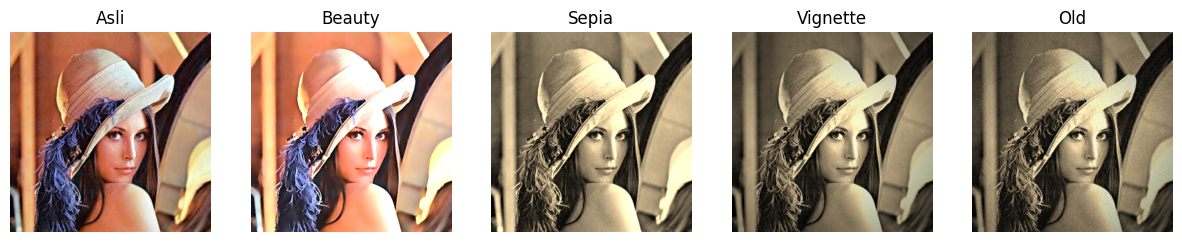

In [ ]:
# 1. Beauty Filter
# Step 1: Smoothing kulit dengan bilateral filter
smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)

# Step 2: Unsharp masking (pertajam mata/bibir)
gaussian = cv.GaussianBlur(smooth, (0,0), 3)
sharpened = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)

# Step 3: Brightness & contrast
alpha = 1.2  # contrast
beta = 15    # brightness
beauty = cv.convertScaleAbs(sharpened, alpha=alpha, beta=beta)

# 2. Old/Vintage Filter
# Step 1: Sepia tone
sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])
sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

# Step 2: Vignette
rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols*0.6)
kernel_y = cv.getGaussianKernel(rows, rows*0.6)
kernel = kernel_y * kernel_x.T
mask = kernel / kernel.max()
vignette = np.copy(sepia)
for i in range(3):
    vignette[:,:,i] = vignette[:,:,i] * mask

# Step 3: Noise/Grain
noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)
show_side_by_side([img, beauty, sepia, vignette, old_img],
                  ["Asli", "Beauty", "Sepia", "Vignette", "Old"])

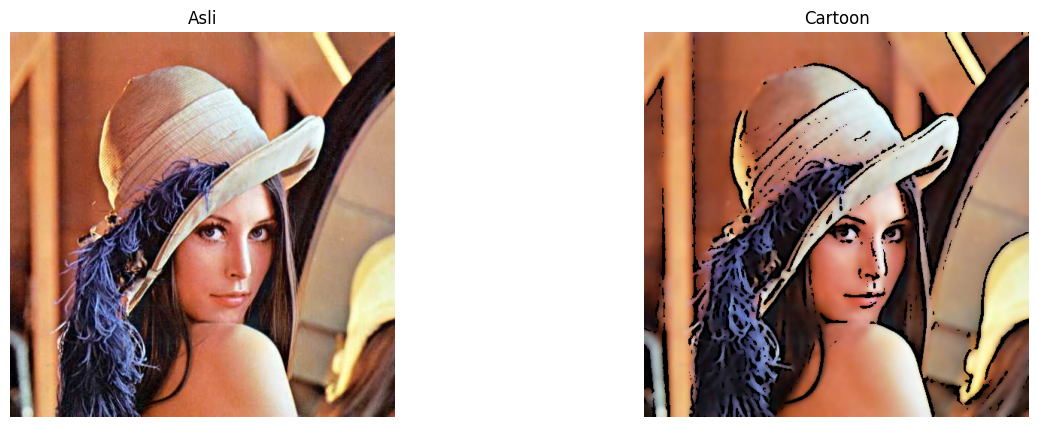

In [ ]:
# Filter anime / cartoon
# Step 1: Edge detection (menggunakan median blur dulu agar gambar menjadi lebih halus)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
blurred = cv.medianBlur(gray, 5)
edges = cv.adaptiveThreshold(blurred, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 9, 9)

# Step 2 : Bilateral filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

#Step 3 : Gabungkan
cartoon = cv.bitwise_and(color, color, mask=edges)

show_side_by_side([img, cartoon],
                  ["Asli", "Cartoon"])

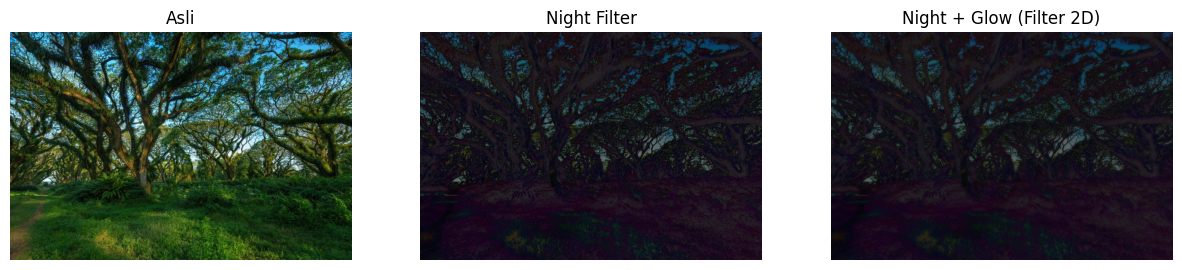

In [ ]:
# Night Filter
img = cv.imread('/content/drive/MyDrive/PCVK-2025/image/djawatan.jpg')

# Step 1 : Gelapkan(Contrast turun, brightness negatif)
night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)

# Step 2 : Tambah bias biru
blue_tint= np.full_like(night, (50,0,100)) # BGR

# Step 3: Efek glow di area terang dengan filter2D (blur kernel)
kernel = np.ones((15,15), np.float32) / 255
glow = cv.filter2D(night, -1, kernel)

# Kombinasikan asli + glow
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

show_side_by_side([img, night, night_glow],
                  ["Asli", "Night Filter", "Night + Glow (Filter 2D)"])

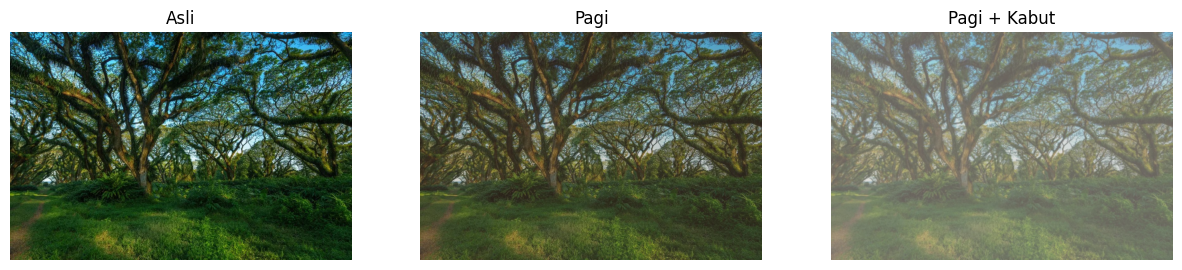

In [ ]:
#Filter Suasana pagi dan Kabut
# Step 1: Kurangi kontras & cerahkan
alpha = 0.9    # contrast
beta = 20      # brightness
soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

# Step 2: Tambahkan warm tone (kemerahan / oranye)
warm_tint = np.full_like(soft, (40, 70, 120))  # BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

# Step 3: Tambahkan haze (kabut tipis) dengan filter2D
# Kernel blur Gaussian-like untuk menciptakan efek kabut
kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T # jadikan 2D kernel
kabut = cv.filter2D(pagi, -1, kernel)

# tambah layer putih untuk kabut lebih nyata
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([img, pagi, kabut],
                  ["Asli", "Pagi", "Pagi + Kabut"])

# TUGAS PRAKTIKUM

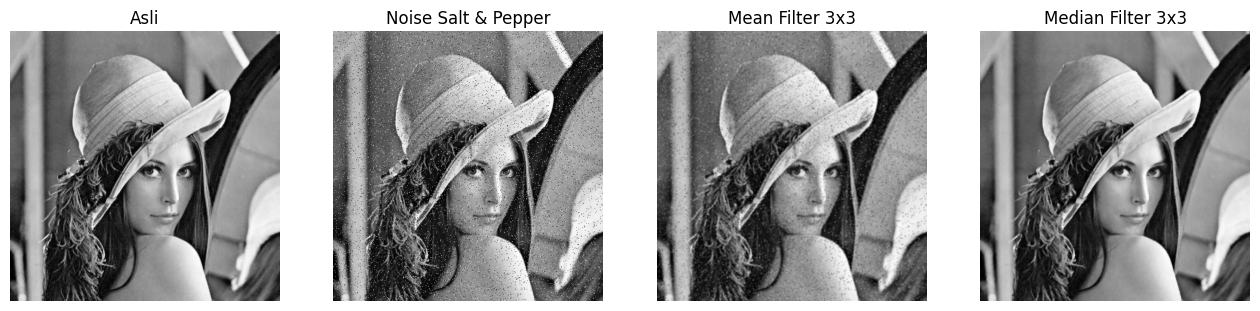

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK-2025/image/lena.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# 1. Tambah noise salt & pepper
np.random.seed(42)
amount = 0.05

noisy = img_gray.copy()
r = np.random.rand(*img_gray.shape)

noisy[r < amount/2] = 0       # pepper (hitam)
noisy[r > 1 - amount/2] = 255 # salt (putih)

# 2. Menambahkan padding replicate dengan ukuran filter 3x3
size = 3
pad = size // 2
padded = np.pad(noisy, pad, mode='edge')

H, W = noisy.shape

# 3. Menghitung mean dan median
mean_result = np.zeros((H, W), dtype=np.float32)
median_result = np.zeros((H, W), dtype=np.uint8)

for i in range(H):
    for j in range(W):
        region = padded[i:i+size, j:j+size]

        mean_result[i, j] = np.mean(region)
        median_result[i, j] = np.median(region)

mean_result = np.clip(mean_result, 0, 255).astype(np.uint8)

show_side_by_side(
    [img_gray, noisy, mean_result, median_result],
    ["Asli", "Noise Salt & Pepper", "Mean Filter 3x3", "Median Filter 3x3"],
    figsize=(16, 4)
)

Median Filter lebih bersih karena menggunakan nilai tengah pada piksel 3×3, sehingga noise hitam-putih tidak terlalu memengaruhi hasil. Sementara Mean Filter menghitung rata-rata, sehingga noise ikut memengaruhi piksel dan membuat citra lebih blur.

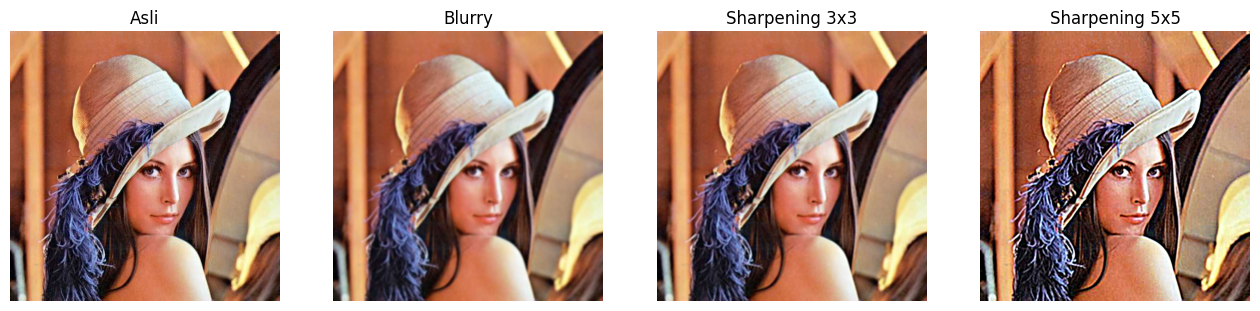

In [ ]:
# Tugas Praktikum 2

# Membuat citra sedikit blur
blur = cv.GaussianBlur(img, (7, 7), 0)

# Kernel sharpening 3x3
kernel_3x3 = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
])

# Kernel sharpening 5x5
kernel_5x5 = np.array([
    [ 0,  0, -1,  0,  0],
    [ 0, -1, -1, -1,  0],
    [-1, -1, 13, -1, -1],
    [ 0, -1, -1, -1,  0],
    [ 0,  0, -1,  0,  0]
])

# Fungsi sharpening
def sharpening(image, kernel):
    size = kernel.shape[0]
    pad = size // 2

    padded = np.pad(
        image,
        ((pad, pad), (pad, pad), (0, 0)),
        mode='edge'
    )

    H, W, C = image.shape
    result = np.zeros((H, W, C), dtype=np.float32)

    for i in range(H):
        for j in range(W):
            region = padded[i:i+size, j:j+size, :]

            for c in range(C):
                result[i, j, c] = np.sum(
                    region[:, :, c] * kernel
                )

    result = np.clip(result, 0, 255).astype(np.uint8)

    return result

# Terapkan sharpening
sharpen_3x3 = sharpening(blur, kernel_3x3)
sharpen_5x5 = sharpening(blur, kernel_5x5)

# Tampilkan hasil
show_side_by_side(
    [img, blur, sharpen_3x3, sharpen_5x5],
    ["Asli", "Blurry", "Sharpening 3x3", "Sharpening 5x5"],
    figsize=(16, 4)
)

Berdasarkan hasil pengamatan, kernel 3×3 menghasilkan tepi yang cukup jelas dengan noise distortion yang lebih rendah, sedangkan kernel 5×5 menghasilkan penajaman yang lebih kuat tetapi dapat meningkatkan noise/distorsi pada citra.  
Jadi, kernel 3×3 paling optimal untuk penggunaan sehari-hari karena memberikan keseimbangan antara kejelasan tepi dan kadar noise yang dihasilkan.

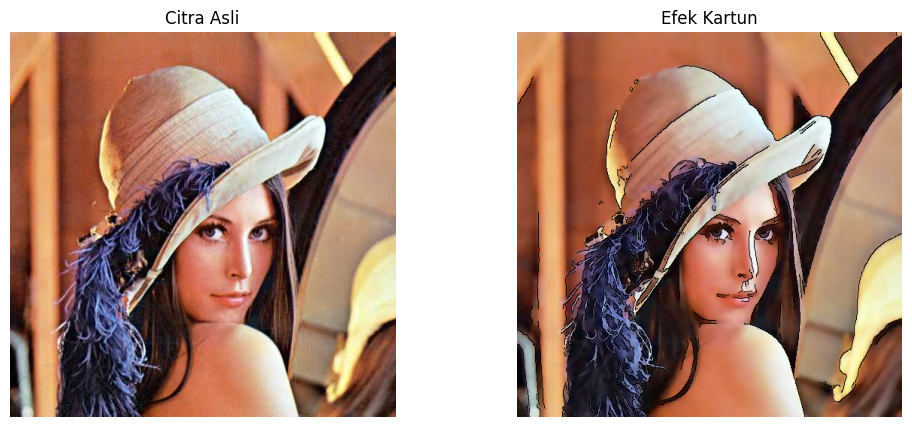

In [ ]:
def kartun(image):
    # Penghalusan warna menggunakan Bilateral Filter
    smooth = cv.bilateralFilter(image, 9, 75, 75)

    # Deteksi garis tepi menggunakan Canny Edge
    gray = cv.cvtColor(smooth, cv.COLOR_BGR2GRAY)
    edges = cv.Canny(gray, 100, 200)

    # Membalik warna edge agar garis menjadi hitam
    edges = cv.bitwise_not(edges)

    # Mengubah edge grayscale menjadi 3 channel
    edges = cv.cvtColor(edges, cv.COLOR_GRAY2BGR)

    # Menggabungkan warna dan garis tepi
    cartoon = cv.multiply(smooth, edges, scale=1/255)

    return cartoon


cartoon_result = kartun(img)

show_side_by_side(
    [img, cartoon_result],
    ["Citra Asli", "Efek Kartun"],
    figsize=(12, 5)
)

In [ ]:
!jupyter nbconvert --to html "/content/drive/MyDrive/PCVK-2025/week6_19.ipynb"

[NbConvertApp] Converting notebook /content/drive/MyDrive/PCVK-2025/week6_19.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 14 image(s).
[NbConvertApp] Writing 8974798 bytes to /content/drive/MyDrive/PCVK-2025/week6_19.html
